In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

<h3>Part1</h3>

In [62]:
data = pd.read_csv('assignment01_digital_services.csv')
data.head()

,observation_id,service,latency_ms,alert_type
0,1,orders,112.70,none
1,2,orders,109.83,none
2,3,telemetry,99.02,none
3,4,telemetry,94.44,none
4,5,telemetry,97.09,none


<h5>a) Identify the observational unit, the relevant population, and each variable as categorical or quantitative. Create a frequency table for <i>alert_type</i> containing counts and percentages.</h5>

In [63]:
print(len(data))
observations = pd.DataFrame({
    'unique values': data.nunique(),
    'null values': data.isna().sum()
})
observations.head()

144


,unique values,null values
observation_id,144,0
service,3,0
latency_ms,143,0
alert_type,4,0



**Observational unit:** Each row represents an observed event containing a latency measurement and a security-alert category for one of three digital services.

**Population:** All digital service events across the digital infrastructure.

**Variable classification:**

- `observation_id`: index
- `service`: categorical
- `latency_ms`: quantitative
- `alert_type`: categorical

In [20]:
frequency_table = data.groupby('alert_type').size().reset_index(name='count')
frequency_table['percentage'] = frequency_table['count'] / len(data) * 100
frequency_table.head()

,alert_type,count,percentage
0,authentication,25,17.361111
1,injection_signature,6,4.166667
2,none,104,72.222222
3,rate_limit,9,6.250000


b) For `latency_ms`, report the sample size, mean, median, sample standard deviation, minimum, Q1, Q3, maximum, and IQR:
<ul>
<li>for all observations combined</li>
<li>separately for each <i>service</i></li>
</ul>


In [41]:
stats = data['latency_ms'].describe()
stats = stats.rename(index={'25%': 'Q1', '50%': 'median', '75%': 'Q3'})
stats['IQR'] = stats['Q3'] - stats['Q1']
stats = stats.to_frame()
stats.head(10)

,latency_ms
count,144.000000
mean,110.111181
std,23.099319
min,75.210000
Q1,95.845000
median,106.930000
Q3,116.885000
max,223.800000
IQR,21.040000


In [39]:
stats_by_service = data.groupby('service')['latency_ms'].describe()
stats_by_service = stats_by_service.rename(columns={
    '25%': 'Q1', 
    '50%': 'median', 
    '75%': 'Q3'
})
stats_by_service['IQR'] = stats_by_service['Q3'] - stats_by_service['Q1']

stats_by_service.head()

,count,mean,std,min,Q1,median,Q3,max,IQR
service,,,,,,,,,
identity,49.0,96.067755,16.120889,75.21,85.3900,93.720,105.1000,154.27,19.71
orders,50.0,122.200000,24.812508,98.53,109.8375,114.525,124.1475,223.80,14.31
telemetry,45.0,111.970889,19.384678,86.78,97.9500,106.920,116.8300,177.87,18.88


<h5>c) Create a histogram of all latency measurements and side-by-side boxplots for the three services. Explain the histogram's axes, bins, and displayed shape and the boxplot's median, box, whiskers, and plotted potential outliers</h5>

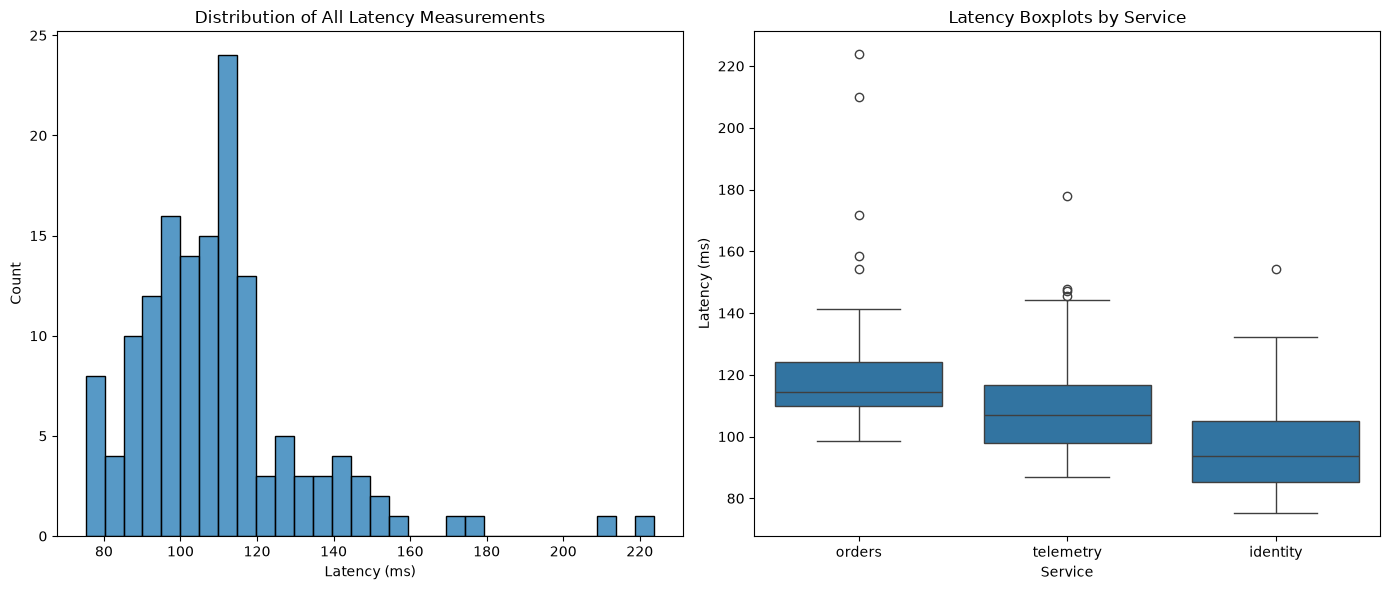

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(data=data, x='latency_ms', bins=30, ax=axes[0])
axes[0].set_title('Distribution of All Latency Measurements')
axes[0].set_xlabel('Latency (ms)')
axes[0].set_ylabel('Count')

sns.boxplot(data=data, x='service', y='latency_ms', ax=axes[1])
axes[1].set_title('Latency Boxplots by Service')
axes[1].set_xlabel('Service')
axes[1].set_ylabel('Latency (ms)')

plt.tight_layout()

plt.show()

The x-axis of the histogram shows latency in milliseconds, while the y-axis shows how frequently these observations happen. The most frequent measurements take place between 110 and 115 ms, seen from the blue bins that represent discrete latency intervals, with almost 25 occurences. The shape of the data is heavily right skewed. Most latency events are situated tightly between 80 ms and 120 ms, though a long tail extends to the right, showing occasional latency spikes reaching beyond 220 ms.

The Boxplots illustrate the distribution of individual services. The horizontal line inside each blue box represents the median latency, showing that the 'orders' service has the highest median, followed by 'telemetry', and then 'identity'. The upper and lower bounds of these boxes capture the 75th and 25th percentiles, forming the interquartile range to show exactly where the middle 50% of the latency data lies for each service. The whiskers extend from the boxes to indicate the spread of the remaining data to the minimum and maximum non-outlier values. The circles positioned beyond these whiskers represent outliers - events near 170 ms, 210 ms and above 220 ms.

<h5>d) Apply the 1.5*IQR rule within each service. Report the IDs and values of potential outliers, retain them in the analysis, and explain why a plotted outlier is not automatically a data error.</h5>

In [ ]:
stats_by_service['lower_bound'] = stats_by_service['Q1'] - 1.5 * stats_by_service['IQR']
stats_by_service['upper_bound'] = stats_by_service['Q3'] + 1.5 * stats_by_service['IQR']

df_with_bounds = data.merge(stats_by_service[['lower_bound', 'upper_bound']], 
                          left_on='service', 
                          right_index=True)

outliers = df_with_bounds[(df_with_bounds['latency_ms'] < df_with_bounds['lower_bound']) | 
                          (df_with_bounds['latency_ms'] > df_with_bounds['upper_bound'])]

outliers.head(20)

# A plotted outlier is not automatically a data error because 
# the data point may be a true, accurate measurement within the observed sample

,observation_id,service,latency_ms,alert_type,lower_bound,upper_bound
18,19,orders,210.10,none,88.3725,145.6125
32,33,telemetry,147.26,authentication,69.6300,145.1500
38,39,telemetry,145.52,none,69.6300,145.1500
59,60,orders,171.59,rate_limit,88.3725,145.6125
65,66,orders,158.59,none,88.3725,145.6125
86,87,orders,154.32,authentication,88.3725,145.6125
87,88,orders,223.80,injection_signature,88.3725,145.6125
119,120,telemetry,147.79,none,69.6300,145.1500
131,132,identity,154.27,none,55.8250,134.6650
132,133,telemetry,177.87,none,69.6300,145.1500


<h5>e) Write a short descriptive comparison of the services. Comment on typical latency, spread, skewness, the relationship between mean and median, and what cannot be generalised from these descriptive differences alone.</h5>


Orders has the highest latency, with a median of 114.53 ms, followed by telemetry (106.92 ms) and identity (93.72 ms). All three services are right-skewed, since their means exceed their medians. The difference is smallest for identity, while orders shows the strongest effect: its mean is 122.20 ms, considerably above its median. This indicates that occasional latency spikes raise the average, so the median better represents typical performance.

<h3>Part2</h3>

In [64]:
data = pd.read_csv('assignment01_smart_building.csv')
data.head()

,measurement_id,hour,zone,outdoor_temp_c,indoor_temp_c,energy_kwh
0,1,1,north,2.14,21.02,41.31
1,2,2,north,1.37,19.99,39.36
2,3,3,north,1.35,20.39,43.58
3,4,4,north,1.59,19.98,45.55
4,5,5,north,2.30,20.74,41.09


##### a) Identify the observational unit and variables. For `indoor_temp_c` and `energy_kwh`, report n, mean, median, and sample standard deviation separately for each zone.

In [65]:
print(len(data))
observations = pd.DataFrame({
    'unique values': data.nunique(),
    'null values': data.isna().sum()
})
observations.head(10)

96


,unique values,null values
measurement_id,96,0
hour,48,0
zone,2,0
outdoor_temp_c,91,0
indoor_temp_c,85,0
energy_kwh,95,0


**Observational unit:** a single hourly sensor reading for a specific building zone.

**Variable classification:**

- `measurement_id`: index
- `hour`: categorical
- `zone`: categorical
- `outdoor_temp_c`: quantitative
- `indoor_temp_c`: quantitative
- `energy_kwh`: quantitative

In [56]:
stats_by_zone = data.groupby('zone')[['indoor_temp_c', 'energy_kwh']].describe()
stats_by_zone = stats_by_zone.rename(columns={
    'count': 'n', 
    '50%': 'median'
}, level=1)
stats_by_zone = stats_by_zone.drop(columns=['min', '25%', '75%', 'max'], level=1)

stats_by_zone.head()

indoor_temp_c                              energy_kwh             \
                  n       mean       std  median          n       mean   
zone                                                                     
north          48.0  21.276458  0.614563  21.240       48.0  39.446458   
south          48.0  22.267083  0.548208  22.285       48.0  37.331042   

                        
            std median  
zone                    
north  3.975399  39.84  
south  4.151442  37.08

##### b) Plot indoor temperature against `hour`, using a separate line for each zone. Describe the time pattern and explain what each axis and line represent 

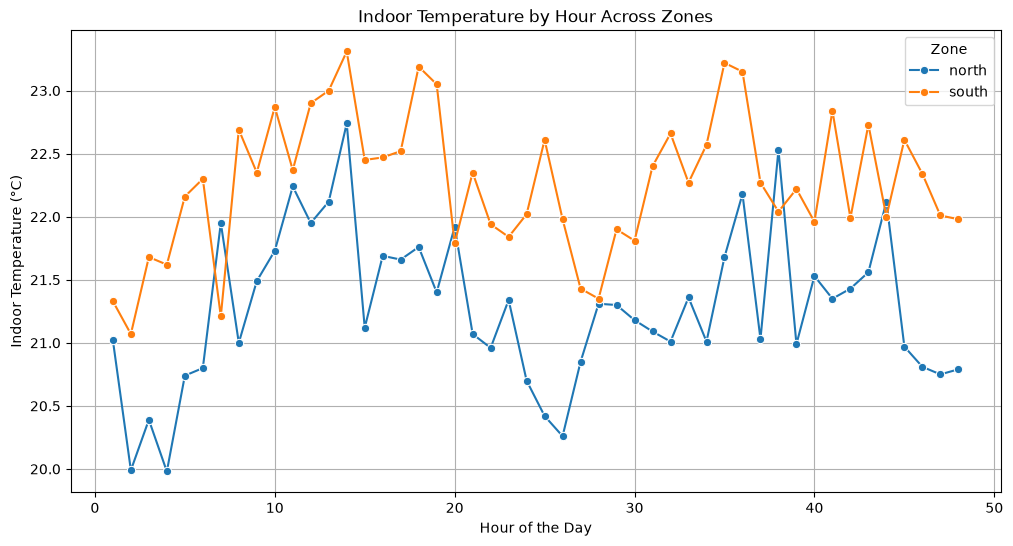

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=data, x='hour', y='indoor_temp_c', hue='zone', marker='o')

plt.title('Indoor Temperature by Hour Across Zones')
plt.xlabel('Hour of the Day')
plt.ylabel('Indoor Temperature (°C)')
plt.legend(title='Zone')
plt.grid(True)
plt.show()

In the chart the x-axis tracks time across a 48-hour period to represent two full days, while the y-axis displays the indoor temperature ranging from 20.0°C to approximately 23.5°C. The orange line represents the "south" zone and the blue line tracking the "north" zone. Temperatures in both areas drop to their lowest points during the early hours of each day (roughly between hours 2‚5 and 24‚28) and peak during the middle and late hours (between 12‚19 and 35‚43). Although both zones heat and cool during the same periods of the dat, the data shows that the south zone remains consistently warmer than the north zone throughout the entire 48-hour window.

##### c) Create a scatterplot of `outdoor_temp_c` against `energy_kwh`, using colour or separate panels for the zones. Describe the direction, form, strength, and unusual points visible in the association.

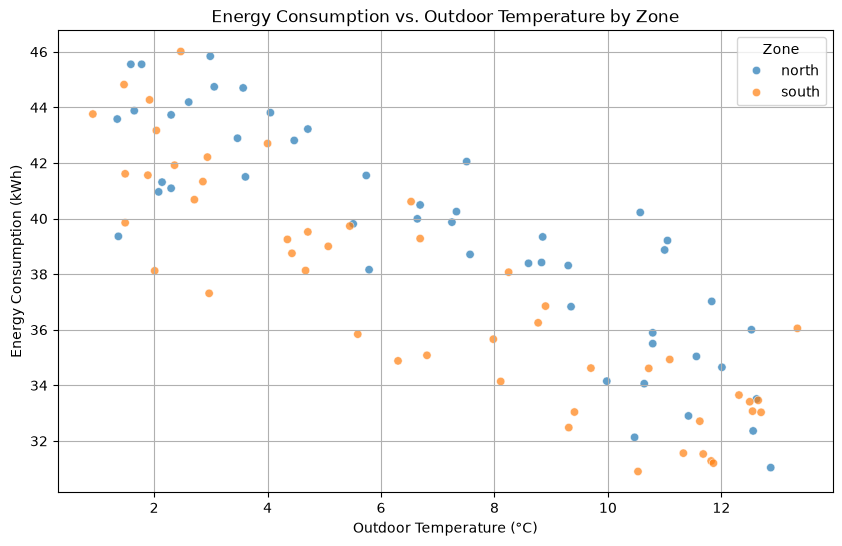

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='outdoor_temp_c', y='energy_kwh', hue='zone', alpha=0.7)

plt.title('Energy Consumption vs. Outdoor Temperature by Zone')
plt.xlabel('Outdoor Temperature (°C)')
plt.ylabel('Energy Consumption (kWh)')
plt.legend(title='Zone')
plt.grid(True)
plt.show()

The scatterplot shows a negative relationship between outdoor temperature and energy consumption. As the temperature rises across the x-axis, energy use on the y-axis decreases for both the north and south zones. The points descend diagonally without significant curvature, forming a relatively wide band that indicates high variance at any given temperature, e.g. the consumption spans from roughly 37 kWh to 46 kWh at 3°C

##### d) Write a short conclusion about temperature stability, differences between zones, and the visible energy–temperature relationship. Do not calculate correlation, fit a regression model, or make causal claims at this stage.


Overall, indoor temperatures were relatively stable in both zones over the 48-hour period. The south zone was consistently warmer than the north zone, with average temperatures of approximately 22.27°C and 21.28°C, respectively. The scatterplot shows a clear negative visual relationship between outdoor temperature and energy consumption. The points are fairly spread out, indicating noticeable variation in consumption at similar outdoor temperatures.

### Part 3

##### a) Define the four elementary outcomes formed from $M$, $M^c$, $A$ and $A^C$. Explain why they are mutually exclusive and exhaustive

The four elementary outcomes are:
- $M \cap A$: A malicious attempt occurs, and an alert is triggered. (Both M and A happen)
- $M \cap A^c$: A malicious attempt occurs, and no alert is triggered. (M happens A doesn't happen)
- $M^c \cap A$: A non-malicious attempt occurs, and an alert is triggered. (M doesn't happen A happens)
- $M^c \cap A^c$: A non-malicious attempt occurs, and no alert is triggered. (Neither M nor A happen)

These events are mutually exclusive because they cannot happen at the same time: when a malicious attemp occurs, we cannot have both an alert triggered and no alert triggered. Respectively, when a non-malicious attempt occurs, we cannot have both an alert and no alert being triggered.

These events are exhaustive because $M$ and $M^C$ cover all possible outcomes for an attempt, while $A$ and $A^C$ show all possible outcomes of a system response

##### b) Construct a labelled 2x2 table of expected counts for 100,000 attempts, including row and column totals. - python code

In [5]:
total_attempts = 100000
p_m = 0.006
p_a_given_m = 0.97
p_a_given_mc = 0.015

count_m = total_attempts * p_m
count_mc = total_attempts - count_m

count_m_a = count_m * p_a_given_m
count_m_ac = count_m - count_m_a

count_mc_a = count_mc * p_a_given_mc
count_mc_ac = count_mc - count_mc_a

count_a = count_m_a + count_mc_a
count_ac = count_m_ac + count_mc_ac

data = {
    'Alert (A)': [count_m_a, count_mc_a, count_a],
    'No Alert (Ac)': [count_m_ac, count_mc_ac, count_ac],
    'Total': [count_m, count_mc, total_attempts]
}

index_labels = ['Malicious (M)', 'Non-malicious (Mc)', 'Total']

df = pd.DataFrame(data, index=index_labels)

df.head()

,Alert (A),No Alert (Ac),Total
Malicious (M),582.0,18.0,600.0
Non-malicious (Mc),1491.0,97909.0,99400.0
Total,2073.0,97927.0,100000.0


##### c) Use the probability model and verify the results from the table:

- $P(M \cap A)$
    - $P(M \cap A) = P(M) * P(A \mid M) = 0.006 * 0.97 = 0.00582$
    - Verification from table: $582$ (column A index M) $/ 100000 = 0.00582$
- $P(A)$
    - $P(A) = P(M \cap A) + P(M^c \cap A) = P(M)P(A \mid M) + P(M^c)P(A \mid M^c) = 0.006 * 0.97 + 0.015(1 - 0.006) = 0.02073$
    - Verification from table: $2073$ (column A index Total) $/ 100000 = 0.02073$
- $P(M \cup A)$
    -  $P(M \cup A) = P(M) + P(A) - P(M \cap A) = 0.006 + 0.02073 - 0.00582 = 0.02091$
    - Verification from table: ($600$ (Column Total index M) + $1491$ (Column A index $M^c$)) / $100000$ = $0.02091$
- $P(M \mid A)$
    - $P(M \mid A) = P(M \cap A) / P(A) = 0.00582 / 0.02073 = 0.28$
    - Verification from table: $582$ (column A index M) / $2073$ (column A index Total) = $582 / 2073 = 0.28$
- $P(M^c \mid A)$
    - $P(M^c \mid A) = P(M^c \cap A) / P(A) = P(M^c)P(A \mid M^c) / P(A) = 0.01491 / 0.02073 = 0.71$
     - Verification from table: $1491$ (column A index $M^c$) / $2073$ (column A index Total) = $0.71$

##### d) Explain the difference between $P(M \mid A)$ and $P(A \mid M)$. Determine whether $M$ and $A$ are independent and whether they are mutually exclusive, justifying both answers numerically.

- $P(A \mid M)$ is the probability that the system triggered an alert given that the attempt was malicious. $P(M \mid A)$ is the probability that the attempt was malicious given that the system triggered an alert.
- $A$ and $M$ are not independent because $P(A \mid M)$ != $P(A)$ -> (0.97 != 0.006)
- $A$ and $M$ are not mutually exclusive because $P(M \cap A)$ != 0  -> (0.00582 != 0)

##### e) Suppose an improved system reduces $P(A \mid M^C)$ to 0.005 while leaving the other inputs unchanged. Recalculate $P(M \mid A)$, compare it with the original value, and explain why both the false-positive rate and the base rate matter.

$P(A) = P(M \cap A) + P(M^c)P(A \mid M^c) = 0.00582 + (0.994 \times 0.005) = 0.01079$

$P(M \mid A) = P(M \cap A) / P(A) = 0.00582/0.01079 = 0.53$

original $P(M \mid A) = 0.28$ 

The recalculated probability of a malicious attempt given an alert is almost doubled compared to the previous one which means that it doubles the reliability of the alerts. The false-positive rate matters because even a small rate applied to the large number of non-malicious attempts can produce many false alerts. The base rate also matters: since malicious attempts are rare, false positives can initially outnumber true positives. Reducing the false-positive rate makes alerts substantially more reliable.

### Part 4

- **AI-use**: We have used Google Gemini in this hand-in to help us generate the code for the plots. After not receiving any compilation errors and visually inspecting the plots, we concluded that the code is correct and there is no need for rejecting or changing it. 
- **Overall conclusion**: The digital-services analysis found that latency differed between services: orders had the highest typical latency, identity had the lowest, and all services were right-skewed because occasional high-latency observations increased the means above the medians, with potential outliers kept. The smart-building analysis showed that indoor temperatures were relatively stable over the two-day period, with the south zone consistently warmer than the north zone. Energy consumption displayed a negative relationship with outdoor temperature. The difference between these 2 types of analysis is that descriptive analysis summarises data that has already been observed, by using graphs and numerical summaries, while probability model analysis predicts possible future outcomes using assumed probabilites. Descriptive analysis is limited because it only summarises the data available without explaining the cause. Probability-model analysis is misleading because it simplifies reality. For example, a model may claim 0.5% false alarm rates, which sounds great, but it hides the reality that in high volume environment, this small percentage means that the system will have to deal with hundreds of false alarms. 